# Student Performance Predictor

Exploratory data analysis, modeling, and evaluation for the UCI
[Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)
dataset (Math course, 395 students).

**Goal:** predict a student's final grade (`G3`, 0-20) and flag students at
risk of failing, early enough that a teacher could intervene.

We compare two framings of the problem:

1. **Early-warning model** — uses only demographic, social, and behavioral
   features available *before* any grades exist. This is the model the app
   deploys, since it is useful at the start of a term.
2. **Full model** — additionally includes the first and second period
   grades (`G1`, `G2`). This sets an upper bound on achievable accuracy and
   illustrates how much signal is lost when grades aren't yet available.


In [1]:
import sys
from pathlib import Path

# Allow `import src...` when running from the notebooks/ directory.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data import load_raw_data
from src.preprocess import clean_data, get_feature_target_split
from src.train import cross_validate_models, train_best_model
from src.evaluate import evaluate_model, get_feature_importance, get_predictions

sns.set_theme(style="whitegrid")
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = {
    "primary": "#4C72B0",
    "secondary": "#DD8452",
    "accent": "#55A868",
    "muted": "#8C8C8C",
}
pd.set_option("display.max_columns", 40)


## 1. Load and clean the data

In [2]:
raw_df = load_raw_data()
df = clean_data(raw_df)
print(f"Shape: {df.shape}")
df.head()


Shape: (395, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,pass
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,1
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,1
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,1


In [3]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


In [4]:
missing = df.isna().sum().sum()
duplicates = df.duplicated().sum()
print(f"Missing values: {missing}")
print(f"Duplicate rows: {duplicates}")
print(f"Pass rate (G3 >= 10): {df['pass'].mean():.1%}")


Missing values: 0
Duplicate rows: 0
Pass rate (G3 >= 10): 67.1%


## 2. Exploratory data analysis

### 2.1 Final grade distribution


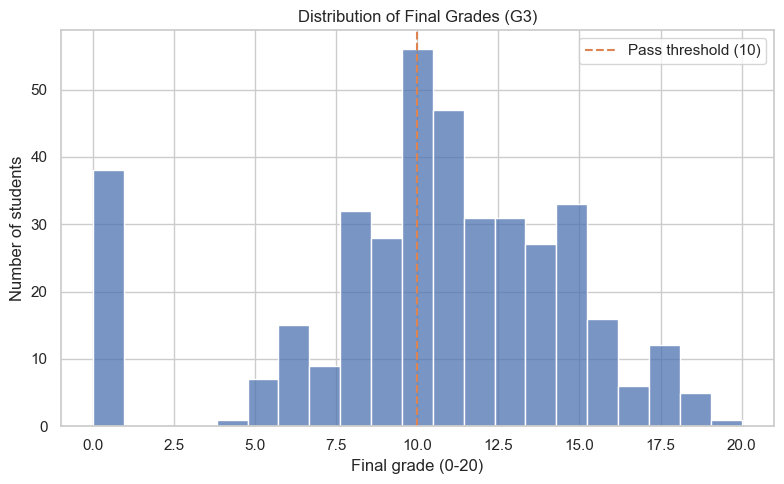

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["G3"], bins=21, color=PALETTE["primary"], ax=ax)
ax.axvline(10, color=PALETTE["secondary"], linestyle="--", label="Pass threshold (10)")
ax.set_title("Distribution of Final Grades (G3)")
ax.set_xlabel("Final grade (0-20)")
ax.set_ylabel("Number of students")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_grade_distribution.png", dpi=150)
plt.show()


### 2.2 Correlation between numeric features and the final grade

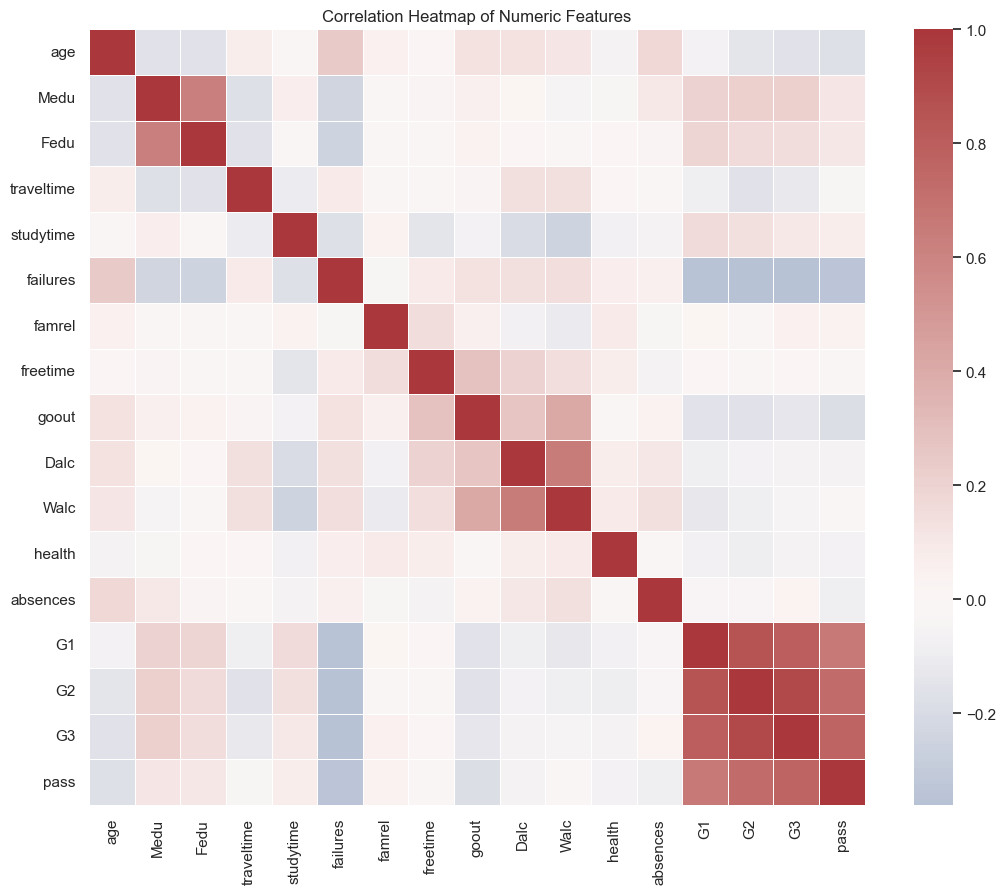

In [6]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr, cmap="vlag", center=0, annot=False, square=True, linewidths=0.4, ax=ax
)
ax.set_title("Correlation Heatmap of Numeric Features")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_correlation_heatmap.png", dpi=150)
plt.show()


In [7]:
corr["G3"].drop(["G3", "G1", "G2"]).sort_values(key=abs, ascending=False)


pass          0.770042
failures     -0.360415
Medu          0.217147
age          -0.161579
Fedu          0.152457
goout        -0.132791
traveltime   -0.117142
studytime     0.097820
health       -0.061335
Dalc         -0.054660
Walc         -0.051939
famrel        0.051363
absences      0.034247
freetime      0.011307
Name: G3, dtype: float64

### 2.3 Absences vs. pass rate

Absences and prior failures are consistently the strongest non-grade
predictors in the literature on this dataset. We bucket absences into bands
to see the relationship more clearly than a raw scatter plot would show.


C:\Users\mulug\AppData\Local\Temp\ipykernel_16332\3264408339.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pass_rate_by_absences = df.groupby("absence_band")["pass"].mean()


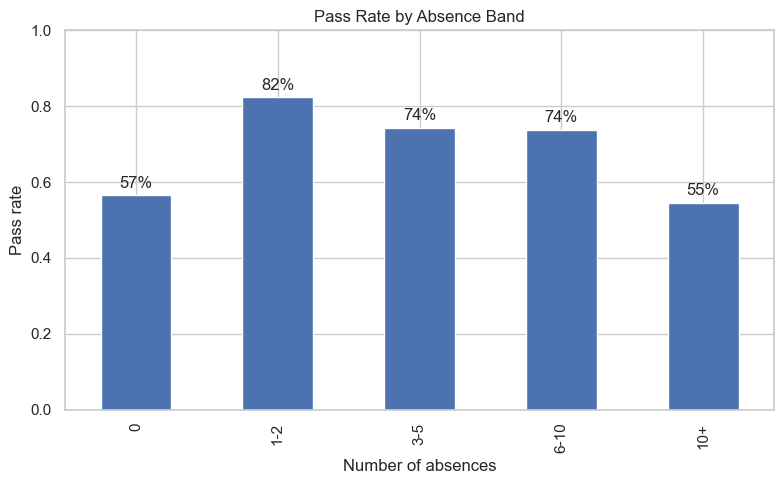

In [8]:
bins = [-1, 0, 2, 5, 10, 100]
labels = ["0", "1-2", "3-5", "6-10", "10+"]
df["absence_band"] = pd.cut(df["absences"], bins=bins, labels=labels)

pass_rate_by_absences = df.groupby("absence_band")["pass"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
pass_rate_by_absences.plot(kind="bar", color=PALETTE["primary"], ax=ax)
ax.set_title("Pass Rate by Absence Band")
ax.set_xlabel("Number of absences")
ax.set_ylabel("Pass rate")
ax.set_ylim(0, 1)
for i, v in enumerate(pass_rate_by_absences):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_absences_vs_pass_rate.png", dpi=150)
plt.show()


### 2.4 Weekly study time vs. final grade

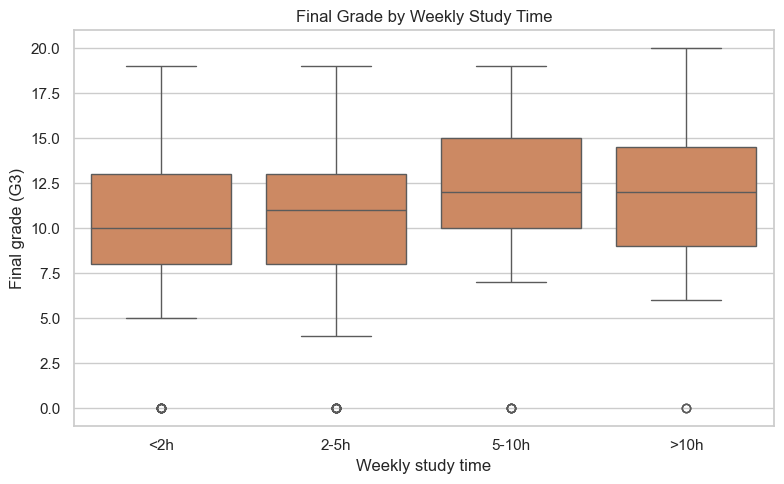

In [9]:
study_labels = {1: "<2h", 2: "2-5h", 3: "5-10h", 4: ">10h"}

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    x=df["studytime"].map(study_labels),
    y=df["G3"],
    order=["<2h", "2-5h", "5-10h", ">10h"],
    color=PALETTE["secondary"],
    ax=ax,
)
ax.set_title("Final Grade by Weekly Study Time")
ax.set_xlabel("Weekly study time")
ax.set_ylabel("Final grade (G3)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_studytime_vs_grade.png", dpi=150)
plt.show()


## 3. Feature sets

We split the engineered dataset into two feature sets:

- `early_warning`: demographic, family, social, and school-related features
  only (available before any grades exist).
- `full`: the same features plus `G1` and `G2`.

Both sets predict the same target, `G3`.


In [10]:
X_early, y = get_feature_target_split(df, feature_set="early_warning")
X_full, _ = get_feature_target_split(df, feature_set="full")
print(f"Early-warning features: {X_early.shape[1]} columns")
print(f"Full features: {X_full.shape[1]} columns")


Early-warning features: 30 columns
Full features: 32 columns


## 4. Model comparison

For each feature set we 5-fold cross-validate four regressors — Linear
Regression, Ridge, Random Forest, and Gradient Boosting — and compare mean
R² on the training data.


In [11]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train_ew, X_test_ew, y_train_ew, y_test_ew = train_test_split(
    X_early, y, test_size=0.2, random_state=RANDOM_STATE
)
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full, y, test_size=0.2, random_state=RANDOM_STATE
)

leaderboard_ew = cross_validate_models(X_train_ew, y_train_ew, "early_warning")
leaderboard_full = cross_validate_models(X_train_full, y_train_full, "full")

leaderboard_ew["feature_set"] = "early_warning"
leaderboard_full["feature_set"] = "full"
comparison = pd.concat([leaderboard_ew, leaderboard_full], ignore_index=True)
comparison


,model,cv_r2_mean,cv_r2_std,feature_set
0,random_forest,0.205509,0.146086,early_warning
1,gradient_boosting,0.180296,0.158340,early_warning
2,ridge,-0.080115,0.214082,early_warning
3,linear_regression,-0.092388,0.223321,early_warning
4,random_forest,0.890110,0.034962,full
5,gradient_boosting,0.880243,0.035084,full
6,ridge,0.805735,0.031929,full
7,linear_regression,0.803852,0.031675,full


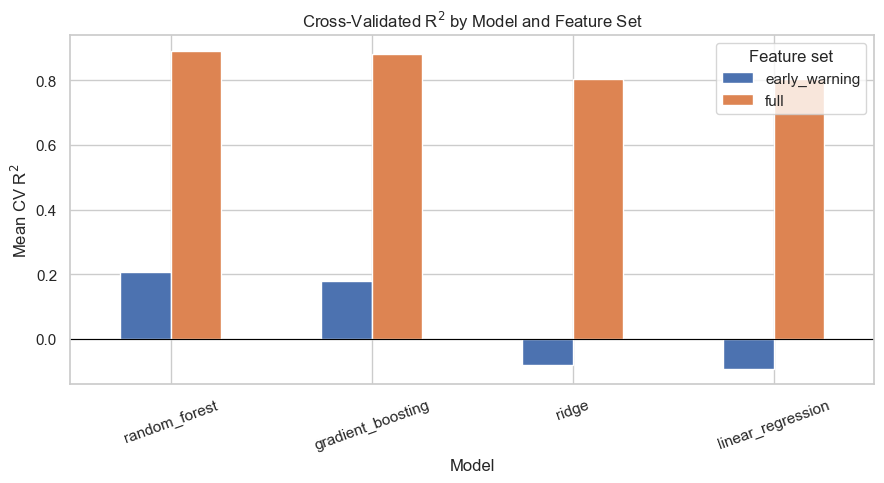

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
pivot = comparison.pivot(index="model", columns="feature_set", values="cv_r2_mean")
pivot = pivot.loc[leaderboard_full["model"]]  # keep ranked order
pivot.plot(kind="bar", ax=ax, color=[PALETTE["primary"], PALETTE["secondary"]])
ax.set_title("Cross-Validated R$^2$ by Model and Feature Set")
ax.set_ylabel("Mean CV R$^2$")
ax.set_xlabel("Model")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(title="Feature set")
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_model_comparison.png", dpi=150)
plt.show()


Including `G1`/`G2` lifts R² dramatically — expected, since period grades are
highly correlated with the final grade. The early-warning set is a much
harder problem, but it's the one that matters for early intervention: by the
time `G1`/`G2` exist, the term is already well underway.

Random Forest is the strongest model on both feature sets, so we select it
for final training.


## 5. Final model training and test-set evaluation

In [13]:
best_pipeline_ew, _ = train_best_model(X_train_ew, y_train_ew, "early_warning")
best_pipeline_full, _ = train_best_model(X_train_full, y_train_full, "full")

metrics_ew = evaluate_model(best_pipeline_ew, X_test_ew, y_test_ew)
metrics_full = evaluate_model(best_pipeline_full, X_test_full, y_test_full)

results = pd.DataFrame([
    {"feature_set": "early_warning", **metrics_ew},
    {"feature_set": "full", **metrics_full},
]).set_index("feature_set")
results


,rmse,mae,r2,pass_fail_accuracy
feature_set,,,,
early_warning,3.778687,3.008679,0.303660,0.670886
full,2.007073,1.191889,0.803544,0.898734


### 5.1 Predicted vs. actual final grade (early-warning model)

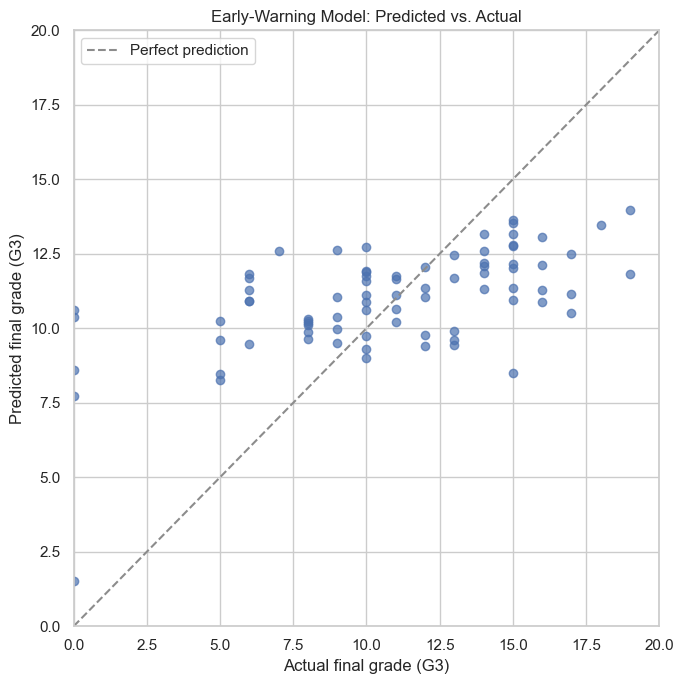

In [14]:
y_pred_ew = get_predictions(best_pipeline_ew, X_test_ew)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test_ew, y_pred_ew, alpha=0.7, color=PALETTE["primary"])
lims = [0, 20]
ax.plot(lims, lims, color=PALETTE["muted"], linestyle="--", label="Perfect prediction")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual final grade (G3)")
ax.set_ylabel("Predicted final grade (G3)")
ax.set_title("Early-Warning Model: Predicted vs. Actual")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_predicted_vs_actual.png", dpi=150)
plt.show()


### 5.2 Feature importance (early-warning model)

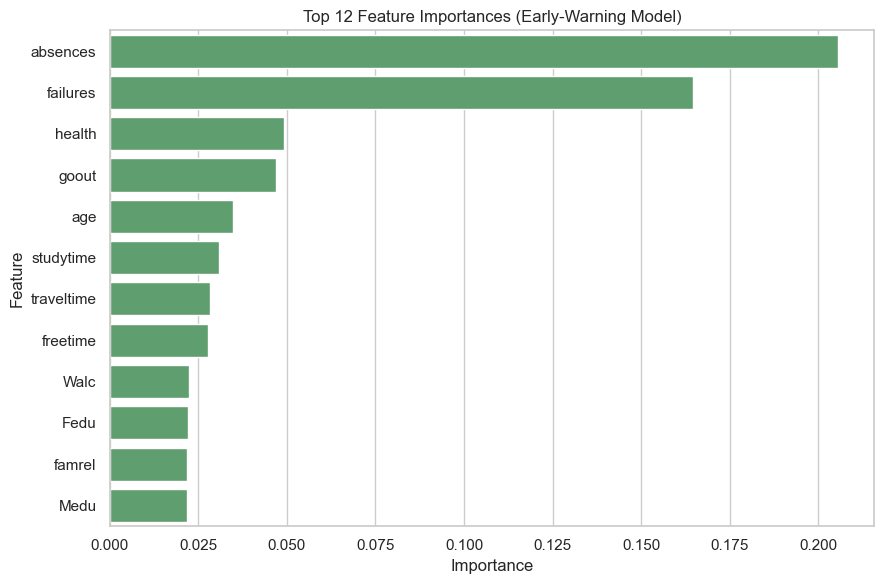

In [15]:
importance_df = get_feature_importance(best_pipeline_ew).head(12)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(
    data=importance_df,
    x="importance",
    y="feature",
    color=PALETTE["accent"],
    ax=ax,
)
ax.set_title("Top 12 Feature Importances (Early-Warning Model)")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_feature_importance.png", dpi=150)
plt.show()


`absences` and `failures` dominate — consistent with the EDA above and with
prior published work on this dataset. These are also the two features a
school could realistically act on early (attendance monitoring, tutoring for
students with prior failures).


## 6. Save the deployed model

In [16]:
import joblib

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_pipeline_ew, MODELS_DIR / "best_model.joblib")
print(f"Saved early-warning model to {MODELS_DIR / 'best_model.joblib'}")


Saved early-warning model to C:\Users\mulug\OneDrive\Desktop\Holder file\end of year show\student-performance-predictor\models\best_model.joblib


## 7. Direct classification (pass/fail)

Section 5 derived a pass/fail call from the regression output (predicted grade rounded and
thresholded at 10). This section instead trains directly on the binary `pass` label, which is
what the Streamlit app's probability gauge, confusion matrix, and ROC curve are built from
(`src/classify.py`, `src/evaluate_classification.py`). Recall on the **fail** class is reported
separately from overall accuracy, since missing an at-risk student is the costlier error for an
early-warning tool.


In [17]:
from src.classify import cross_validate_classifiers, get_classification_split, train_best_classifier
from src.evaluate_classification import (
    evaluate_classifier,
    get_confusion_matrix,
    get_roc_curve_data,
)

X_train_cls_ew, X_test_cls_ew, y_train_cls_ew, y_test_cls_ew = get_classification_split(df, "early_warning")
X_train_cls_full, X_test_cls_full, y_train_cls_full, y_test_cls_full = get_classification_split(df, "full")

cls_leaderboard_ew = cross_validate_classifiers(X_train_cls_ew, y_train_cls_ew, "early_warning")
cls_leaderboard_full = cross_validate_classifiers(X_train_cls_full, y_train_cls_full, "full")

cls_leaderboard_ew["feature_set"] = "early_warning"
cls_leaderboard_full["feature_set"] = "full"
pd.concat([cls_leaderboard_ew, cls_leaderboard_full], ignore_index=True)


,model,cv_roc_auc_mean,cv_roc_auc_std,feature_set
0,random_forest,0.729179,0.080694,early_warning
1,logistic_regression,0.712330,0.095245,early_warning
2,gradient_boosting,0.666315,0.053323,early_warning
3,gradient_boosting,0.976770,0.015779,full
4,logistic_regression,0.975115,0.012862,full
5,random_forest,0.972419,0.025477,full


In [18]:
best_classifier_ew, _ = train_best_classifier(X_train_cls_ew, y_train_cls_ew, "early_warning")
best_classifier_full, _ = train_best_classifier(X_train_cls_full, y_train_cls_full, "full")

cls_metrics_ew = evaluate_classifier(best_classifier_ew, X_test_cls_ew, y_test_cls_ew)
cls_metrics_full = evaluate_classifier(best_classifier_full, X_test_cls_full, y_test_cls_full)

cls_results = pd.DataFrame([
    {"scenario": "A - early_warning", **cls_metrics_ew},
    {"scenario": "B - full", **cls_metrics_full},
]).set_index("scenario")
cls_results


,accuracy,precision_pass,recall_pass,f1_pass,recall_fail,roc_auc
scenario,,,,,,
A - early_warning,0.696203,0.754386,0.811321,0.781818,0.461538,0.653846
B - full,0.886076,0.958333,0.867925,0.910891,0.923077,0.942671


Scenario A catches only about half of the students who will actually fail (`recall_fail`), even
with class-balanced training -- consistent with the regression framing's modest R² for the same
feature set. Scenario B's much higher fail-recall is again driven by `G1`/`G2` already containing
most of the answer, not by the demographic/behavioral features becoming more informative.


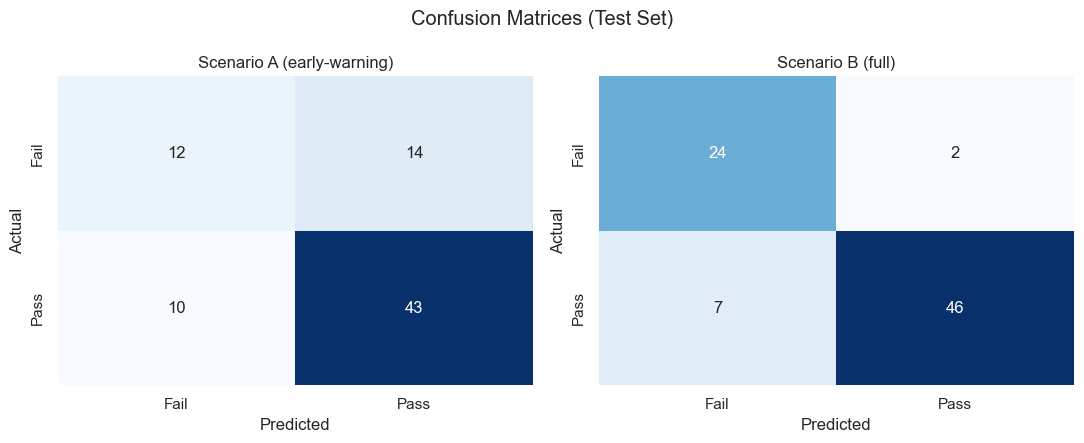

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pipeline, X_test, y_test) in zip(
    axes,
    [
        ("Scenario A (early-warning)", best_classifier_ew, X_test_cls_ew, y_test_cls_ew),
        ("Scenario B (full)", best_classifier_full, X_test_cls_full, y_test_cls_full),
    ],
):
    cm = get_confusion_matrix(pipeline, X_test, y_test)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"], ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.suptitle("Confusion Matrices (Test Set)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_confusion_matrices.png", dpi=150)
plt.show()


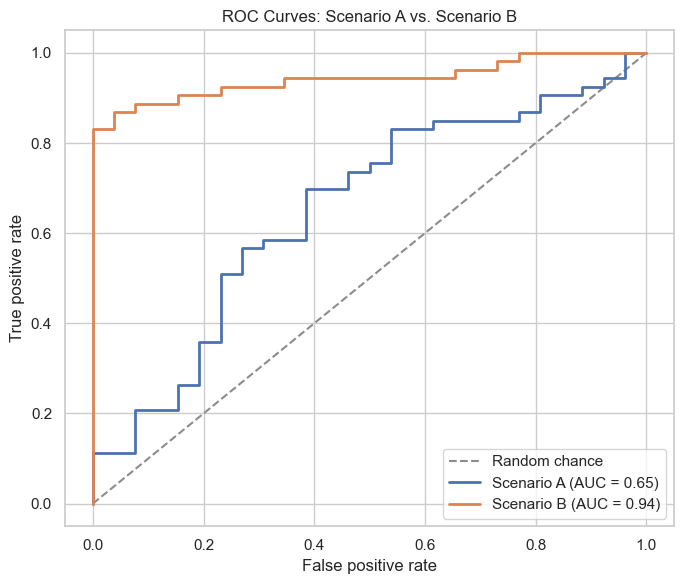

In [20]:
fig, ax = plt.subplots(figsize=(7, 6))
roc_ew = get_roc_curve_data(best_classifier_ew, X_test_cls_ew, y_test_cls_ew)
roc_full = get_roc_curve_data(best_classifier_full, X_test_cls_full, y_test_cls_full)

ax.plot([0, 1], [0, 1], linestyle="--", color=PALETTE["muted"], label="Random chance")
ax.plot(roc_ew.fpr, roc_ew.tpr, color=PALETTE["primary"], linewidth=2, label=f"Scenario A (AUC = {roc_ew.auc:.2f})")
ax.plot(roc_full.fpr, roc_full.tpr, color=PALETTE["secondary"], linewidth=2, label=f"Scenario B (AUC = {roc_full.auc:.2f})")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC Curves: Scenario A vs. Scenario B")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_roc_curves.png", dpi=150)
plt.show()


### 7.1 Save the deployed classifier

The Scenario A classifier (not the regressor saved in Section 6) is what the Streamlit app's
Predictor page actually uses for its probability gauge and SHAP explanations.


In [21]:
joblib.dump(best_classifier_ew, MODELS_DIR / "best_classifier.joblib")
print(f"Saved early-warning classifier to {MODELS_DIR / 'best_classifier.joblib'}")


Saved early-warning classifier to C:\Users\mulug\OneDrive\Desktop\Holder file\end of year show\student-performance-predictor\models\best_classifier.joblib


## 8. Conclusions

- The **early-warning model** (demographic/behavioral features only)
  achieves R² ≈ 0.30 and ~67% pass/fail accuracy — modest, but usable as a
  screening signal before any grades exist.
- The **full model** (adding `G1`/`G2`) achieves R² ≈ 0.80 and ~90%
  pass/fail accuracy, confirming that period grades carry most of the
  predictive signal, as expected.
- `absences` and `failures` are the most important non-grade predictors,
  suggesting attendance monitoring and support for students with prior
  failures are the most actionable early interventions.
- The deployed Streamlit app (`app/app.py`) uses the early-warning model, so
  it can flag at-risk students at the start of a term, before any grades are
  available.

- **Direct classification confirms the regression finding from a different angle**: Scenario A's classifier catches only ~46% of students who will actually fail (recall on the fail class), even with class-balanced training -- a weak screen on its own, better used to prioritize review than to make a final call.